# Proyecto final de Bioinformática
## Clasificación de cinco tipos de cáncer mediante expresión genética y machine learning

### Introducción

El cáncer se produce cuando algunas células comienzan a crecer de manera descontrolada. Aunque existen distintos tipos de cáncer, cada uno presenta características genéticas que pueden ayudarnos a diferenciarlos.

El paper de Hoadley et al. (2018), Cell-of-Origin Patterns Dominate the Molecular Classification of 10,000 Tumors from 33 Types of Cancer, analizó aproximadamente 10.000 tumores de 33 tipos para estudiar sus semejanzas y diferencias moleculares.

Nuestro dataset no procede directamente de ese artículo: utilizamos Gene Expression Cancer RNA-Seq (Fiorini, 2016), descargado de UCI, con 801 muestras de cinco clases tumorales y 20.531 variables de expresión, derivadas del proyecto TCGA. El trabajo de Hoadley se usa como referencia científica.

El conjunto de datos contiene **801 muestras de cinco tipos de cáncer y 20.531 mediciones de expresión genética**.

La expresión genética nos indica qué tan activo está cada gen en una muestra.

### El objetivo será tratar de responder a estas preguntas:

1. ¿Podemos identificar 5 diferentes tipos de cáncer utilizando una cantidad reducida de genes, sin perder precisión en la clasificación?

2. ¿Los 5 tipos de cáncer presentan patrones de expresión distingibles?
3. ¿Cuántos genes necesitamos para conseguir una buena precisión en Random Forest?
4. ¿Qué genes son los más importantes para diferenciar los tipos de cáncer?
5. ¿Qué tipos de cáncer presentan características genéticas más parecidas y cuáles son más diferentes?
6. ¿Qué tipos de cáncer confunde más la inteligencia artificial y por qué?

### Herramientas que utilizaremos
Preparación y normalización de datos, PCA, K-Means, Random Forest y matriz de confusión.


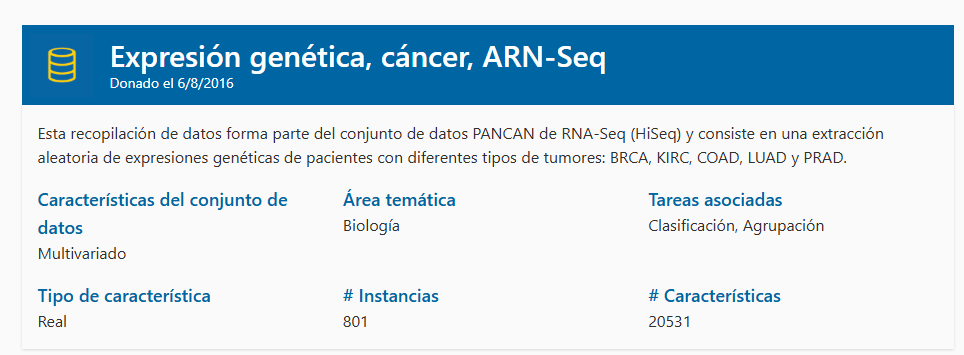

##Paso 1. Importar librerías y cargar el dataset

In [1]:

# Importamos las librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score,
    accuracy_score, balanced_accuracy_score,
    ConfusionMatrixDisplay
)

# Descargamos los datos originales desde UCI
!wget -q --show-progress "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip" -O cancer.zip

# Descomprimimos los archivos
!unzip -oq cancer.zip
!tar -xzf TCGA-PANCAN-HiSeq-801x20531.tar.gz

# Abrimos las dos tablas
carpeta = "TCGA-PANCAN-HiSeq-801x20531"

datos = pd.read_csv(f"{carpeta}/data.csv")
etiquetas = pd.read_csv(f"{carpeta}/labels.csv")

# Comprobamos las dimensiones
print("Cantidad de muestras:", datos.shape[0])
print("Cantidad de genes:", datos.shape[1] - 1)

# Mostramos algunas columnas
print("\nPrimeras muestras:")
display(datos.iloc[:5, :6])

# Mostramos las etiquetas
print("\nTipos de cáncer:")
display(etiquetas.head())

# Identificamos los tipos de cáncer presentes
print("\nTipos de cáncer presentes:")
print(etiquetas["Class"].unique())

# Contamos las muestras de cada tipo de cáncer
print("\nMuestras por tipo de cáncer:")
print(etiquetas["Class"].value_counts())

# Comprobamos los tipos de datos
print("\nTipos de datos:")
print(datos.dtypes.value_counts())


cancer.zip              [               <=>  ]  69.48M  18.9MB/s    in 3.7s    
Cantidad de muestras: 801
Cantidad de genes: 20531

Primeras muestras:


,Unnamed: 0,gene_0,gene_1,gene_2,gene_3,gene_4
0,sample_0,0.0,2.017209,3.265527,5.478487,10.431999
1,sample_1,0.0,0.592732,1.588421,7.586157,9.623011
2,sample_2,0.0,3.511759,4.327199,6.881787,9.870730
3,sample_3,0.0,3.663618,4.507649,6.659068,10.196184
4,sample_4,0.0,2.655741,2.821547,6.539454,9.738265



Tipos de cáncer:


,Unnamed: 0,Class
0,sample_0,PRAD
1,sample_1,LUAD
2,sample_2,PRAD
3,sample_3,PRAD
4,sample_4,BRCA



Tipos de cáncer presentes:
['PRAD' 'LUAD' 'BRCA' 'KIRC' 'COAD']

Muestras por tipo de cáncer:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Tipos de datos:
float64    20531
object         1
Name: count, dtype: int64


Las clases que encontramos son:

*   BRCA: Cáncer de	mama
*   KIRC: Cáncer de riñón

*   COAD: Cáncer de colon
*   LUAD: Cáncer de pulmón


*   PRAD: Cáncer de próstata






## Paso 2. Buscar valores faltantes y duplicados


Antes de hacer un análisis, vamos a comprobar si faltan datos o hay muestras repetidas.

In [2]:

# Comprobamos si faltan valores
print("Valores faltantes:", datos.isna().sum().sum())

# Buscamos muestras repetidas
print("Muestras duplicadas:", datos.duplicated().sum())

# Revisamos los valores mínimos y máximos
genes = datos.drop(columns=["Unnamed: 0"])

print("Valor mínimo:", genes.min().min())
print("Valor máximo:", genes.max().max())


Valores faltantes: 0
Muestras duplicadas: 0
Valor mínimo: 0.0
Valor máximo: 20.7788287118


Los datos están completos y podemos continuar. No necesitamos eliminar muestras por valores faltantes.

##Paso 3. Preparar los datos para machine learning


Vamos a separar la información genética (X) del tipo de cáncer (y) y convertir las etiquetas de los cánceres en números.

In [3]:
# X contiene los valores de expresión genética
X = datos.drop(columns=["Unnamed: 0"])

# y contiene el tipo de cáncer
y = etiquetas["Class"]

# Convertimos los nombres de cáncer a números
codificador = LabelEncoder()
y = codificador.fit_transform(y)

# Comprobamos el resultado
print("Dimensiones de X:", X.shape)
print("Cantidad de etiquetas:", len(y))

print("\nCódigos de los cánceres:")
for numero, cancer in enumerate(codificador.classes_):
    print(numero, "=", cancer)


Dimensiones de X: (801, 20531)
Cantidad de etiquetas: 801

Códigos de los cánceres:
0 = BRCA
1 = COAD
2 = KIRC
3 = LUAD
4 = PRAD


Entonces:

x: contiene los 20.531 genes de cada muestra.



y: indica a qué tipo de cáncer pertenece cada muestra.



LabelEncoder(): convierte los nombres de los cánceres en números para que los algoritmos puedan utilizarlos.

##Paso 4. Normalizar los datos

Vamos a llevar los valores de expresión genética a una escala entre 0 y 1. Esto evita que los genes con valores más altos tengan más influencia simplemente por su escala.

In [4]:
# Normalizamos los genes
normalizador = MinMaxScaler() #función que usamos en clases
X_normalizado = normalizador.fit_transform(X)

# Comprobamos el resultado
print("Dimensiones:", X_normalizado.shape)
print("Valor mínimo:", X_normalizado.min())
print("Valor máximo:", X_normalizado.max())


Dimensiones: (801, 20531)
Valor mínimo: 0.0
Valor máximo: 1.0000000000000004


## Paso 5. Aplicar PCA


Tenemos 20.531 genes por muestra,demasiados para graficarlos. PCA nos permite resumir esa información en dos componentes y representar las 801 muestras en un gráfico.

Cada punto será una muestra de tumor y cada color representará un tipo de cáncer.

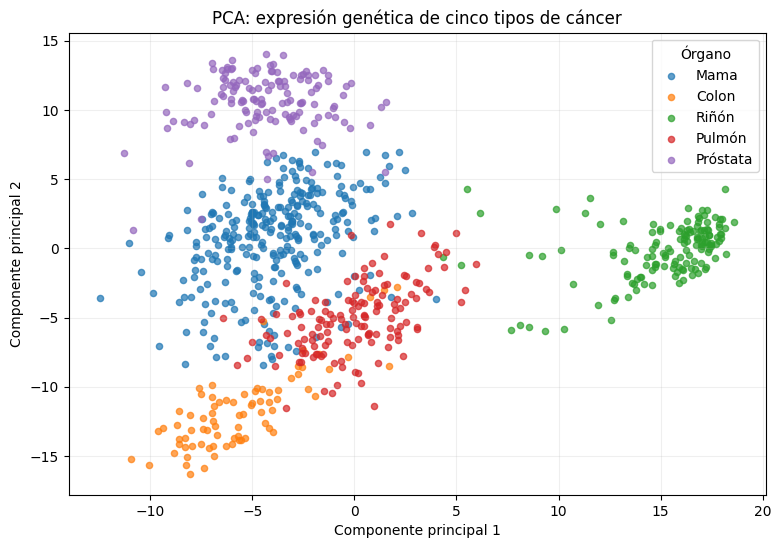

Varianza explicada por PC1: 12.69 %
Varianza explicada por PC2: 9.4 %
Varianza total explicada: 22.1 %


In [5]:
# Reducimos los 20.531 genes a 2 componentes
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_normalizado)

# Diccionario para traducir los códigos
nombres_cancer = {
    "BRCA": "Mama",
    "COAD": "Colon",
    "KIRC": "Riñón",
    "LUAD": "Pulmón",
    "PRAD": "Próstata"
}

# Graficamos las muestras
plt.figure(figsize=(9, 6))

for i, cancer in enumerate(codificador.classes_):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=nombres_cancer[cancer],
        alpha=0.7,
        s=20
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("PCA: expresión genética de cinco tipos de cáncer")
plt.legend(title="Órgano")
plt.grid(alpha=0.2)
plt.show()

# Información conservada por PCA
print("Varianza explicada por PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Varianza explicada por PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Varianza total explicada:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Vemos que los cinco tipos de cáncer presentan patrones de expresión genética diferentes. El cáncer de riñón aparece claramente separado, mientras que los cánceres de mama y pulmón presentan cierta superposición. Los dos componentes principales explican el 22,1 % de la variación total, por lo que este gráfico nos permite explorar semejanzas, pero no representa toda la información genética disponible.

##Paso 6. ¿Cuántos componentes necesitamos?

Antes de usar K-Means, vamos a comprobar cuántos componentes de PCA necesitamos para conservar el 80 % de la información. Así no nos quedamos solamente con el 22,1 % del gráfico.

In [6]:
# Calculamos los primeros 200 componentes
pca_200 = PCA(n_components=200, random_state=42)
X_pca_200 = pca_200.fit_transform(X_normalizado)

# Sumamos la información que conserva cada componente
varianza_acumulada = np.cumsum(
    pca_200.explained_variance_ratio_
)

# Buscamos cuántos componentes conservan el 80 %
cantidad = np.searchsorted(varianza_acumulada, 0.80) + 1

if cantidad <= 200:
    print("Componentes necesarios para conservar el 80 %:", cantidad)
else:
    print("Con 200 componentes todavía no llegamos al 80 %.")

print("Información conservada con 200 componentes:",
      round(varianza_acumulada[-1] * 100, 2), "%")


Componentes necesarios para conservar el 80 %: 157
Información conservada con 200 componentes: 82.86 %


 Descubrimos que podemos pasar de 20.531 genes a **157 componentes**, conservando el 80 % de la variación de los datos. Estos componentes no son genes individuales, sino combinaciones de los genes originales.

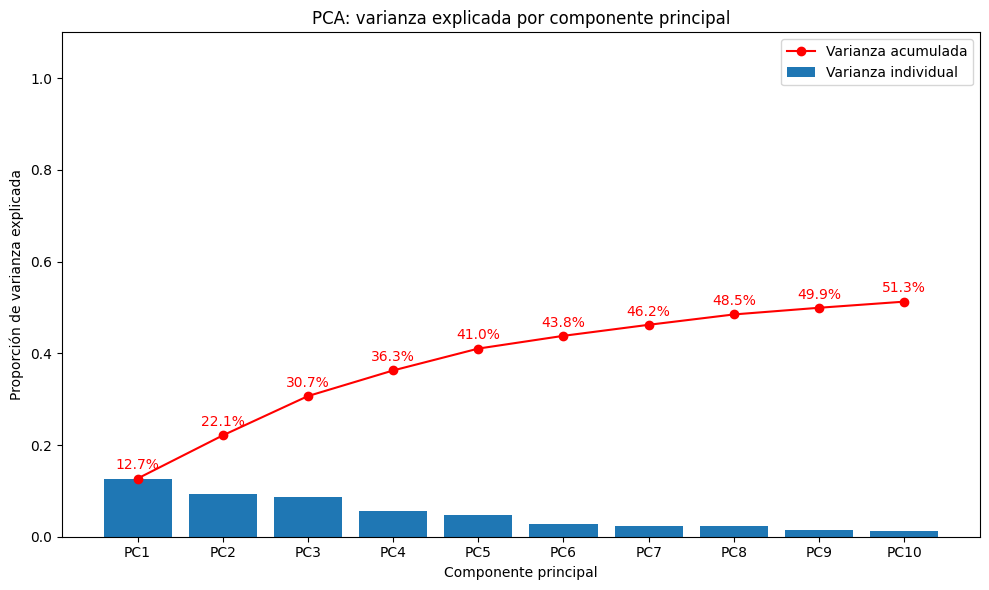

In [12]:

# Seleccionamos las primeras 10 componentes del PCA, para verlo bien
var = pca_200.explained_variance_ratio_[:10]
acum = np.cumsum(var)
pcs = np.arange(1, len(var) + 1)

# Graficamos la varianza individual y acumulada
plt.figure(figsize=(10, 6))
plt.bar(pcs, var, label="Varianza individual")
plt.plot(pcs, acum, marker="o", color="red",
         label="Varianza acumulada")

# Mostramos el porcentaje acumulado sobre cada punto
for pc, a in zip(pcs, acum):
    plt.text(pc, a + 0.02, f"{a:.1%}",
             ha="center", color="red")

plt.xticks(pcs, [f"PC{i}" for i in pcs])
plt.ylim(0, 1.1)
plt.xlabel("Componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("PCA: varianza explicada por componente principal")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


###Obtenemos los vectores de carga

In [13]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(
    loadings,
    columns=["PC1", "PC2"],
    index=X.columns
)

print("Vectores de carga (Loadings):")
display(loadings_df.head(10))


Vectores de carga (Loadings):


,PC1,PC2
gene_0,8.788367e-04,-2.071807e-04
gene_1,-4.819158e-03,1.485518e-03
gene_2,-5.710326e-03,4.569338e-03
gene_3,-5.201023e-03,-6.874206e-03
gene_4,-1.049758e-02,-6.049715e-03
gene_5,-3.115582e-22,-1.056855e-20
gene_6,-4.238085e-03,4.036704e-03
gene_7,2.746995e-03,1.940763e-03
gene_8,-3.034921e-05,-4.500951e-04
gene_9,-2.112707e-04,-2.387674e-04


Con el código que vimos en la práctica nos quedamos un poco cortos porque solo analiza los 10 primeros genes, y hay mas de 20 mil. Para que sea más confiable, usaremos el siguiente código para ver los vectores de carga verdaderos:

In [17]:

# Obtener los vectores de carga de PC1 y PC2
loadings = pca.components_.T

# Crear un DataFrame con todos los genes
loadings_df = pd.DataFrame(
    loadings,
    columns=["PC1", "PC2"],
    index=X.columns
)

# Ordenar los genes según su importancia en PC1
pc1_ordenado = loadings_df.reindex(
    loadings_df["PC1"].abs().sort_values(ascending=False).index
)

# Ordenar los genes según su importancia en PC2
pc2_ordenado = loadings_df.reindex(
    loadings_df["PC2"].abs().sort_values(ascending=False).index
)

print("Genes más relevantes para PC1:")
display(pc1_ordenado)

print("\nGenes más relevantes para PC2:")
display(pc2_ordenado)


Genes más relevantes para PC1:


,PC1,PC2
gene_1858,0.037822,-0.006162
gene_219,0.036245,0.000744
gene_13818,0.036113,-0.000531
gene_1510,0.035227,0.000074
gene_220,0.035191,0.000218
...,...,...
gene_16810,0.000000,0.000000
gene_16809,0.000000,0.000000
gene_16808,0.000000,0.000000
gene_16789,0.000000,0.000000



Genes más relevantes para PC2:


,PC1,PC2
gene_9175,-0.012833,0.035381
gene_9176,-0.012533,0.033119
gene_3737,-0.010015,0.032069
gene_4456,-0.009059,0.031206
gene_12848,-0.008975,0.030820
...,...,...
gene_16856,0.000000,0.000000
gene_16738,0.000000,0.000000
gene_16700,0.000000,0.000000
gene_16701,0.000000,0.000000


Resumiendo:

In [18]:
# Gen más relevante para PC1
gen_pc1 = loadings_df["PC1"].abs().idxmax() #se usa para encontrar el gen con mayor carga absoluta

# Gen más relevante para PC2
gen_pc2 = loadings_df["PC2"].abs().idxmax()

print("Gen más relevante para PC1:", gen_pc1)
print("Carga:", loadings_df.loc[gen_pc1, "PC1"])

print("\nGen más relevante para PC2:", gen_pc2)
print("Carga:", loadings_df.loc[gen_pc2, "PC2"])

Gen más relevante para PC1: gene_1858
Carga: 0.03782232179441356

Gen más relevante para PC2: gene_9175
Carga: 0.03538076719337516


###Hacemos el biplot

Como tenemos 20.531 genes, si dibujamos una flecha por cada uno, el gráfico sería ilegible. Por eso vamos a representar los 3 genes con mayor carga absoluta en PC1 y los 3 de PC2.

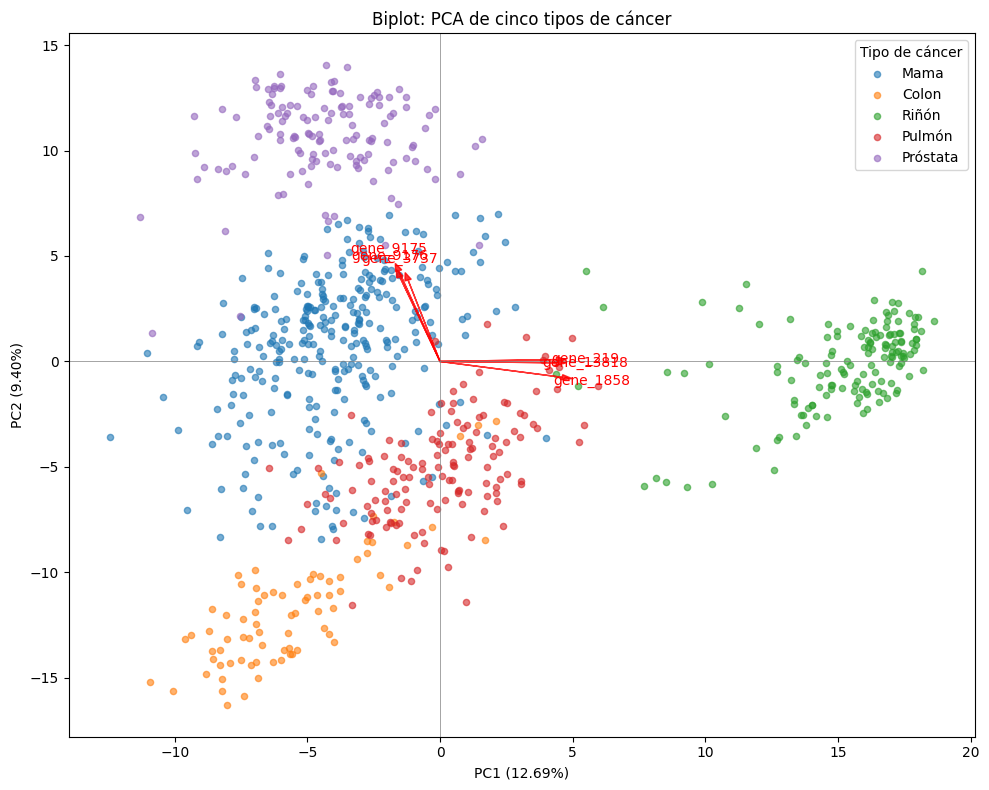

In [19]:

plt.figure(figsize=(10, 8))

# Graficar las muestras de los cinco tipos de cáncer
for i, cancer in enumerate(codificador.classes_):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=nombres_cancer[cancer],
        alpha=0.6,
        s=20
    )

# Obtener los vectores de carga
loadings = pca.components_.T

# Seleccionar los 3 genes más relevantes de cada componente
indices_pc1 = np.argsort(np.abs(loadings[:, 0]))[-3:]
indices_pc2 = np.argsort(np.abs(loadings[:, 1]))[-3:]

indices = np.unique(np.concatenate((indices_pc1, indices_pc2)))

# Factor para agrandar las flechas
rango = max(np.ptp(X_pca[:, 0]), np.ptp(X_pca[:, 1]))
escala = rango * 0.16 / np.max(np.abs(loadings[indices]))

# Dibujar los vectores de carga
for i in indices:
    lx = loadings[i, 0]
    ly = loadings[i, 1]

    plt.arrow(
        0, 0,
        lx * escala,
        ly * escala,
        color="red",
        alpha=0.8,
        head_width=rango * 0.008,
        length_includes_head=True
    )

    plt.text(
        lx * escala * 1.15,
        ly * escala * 1.15,
        X.columns[i],
        color="red",
        ha="center",
        va="center"
    )

plt.axhline(0, color="grey", lw=0.5)
plt.axvline(0, color="grey", lw=0.5)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")

plt.title("Biplot: PCA de cinco tipos de cáncer")
plt.legend(title="Tipo de cáncer")

plt.tight_layout()
plt.show()


Ampliandolo:

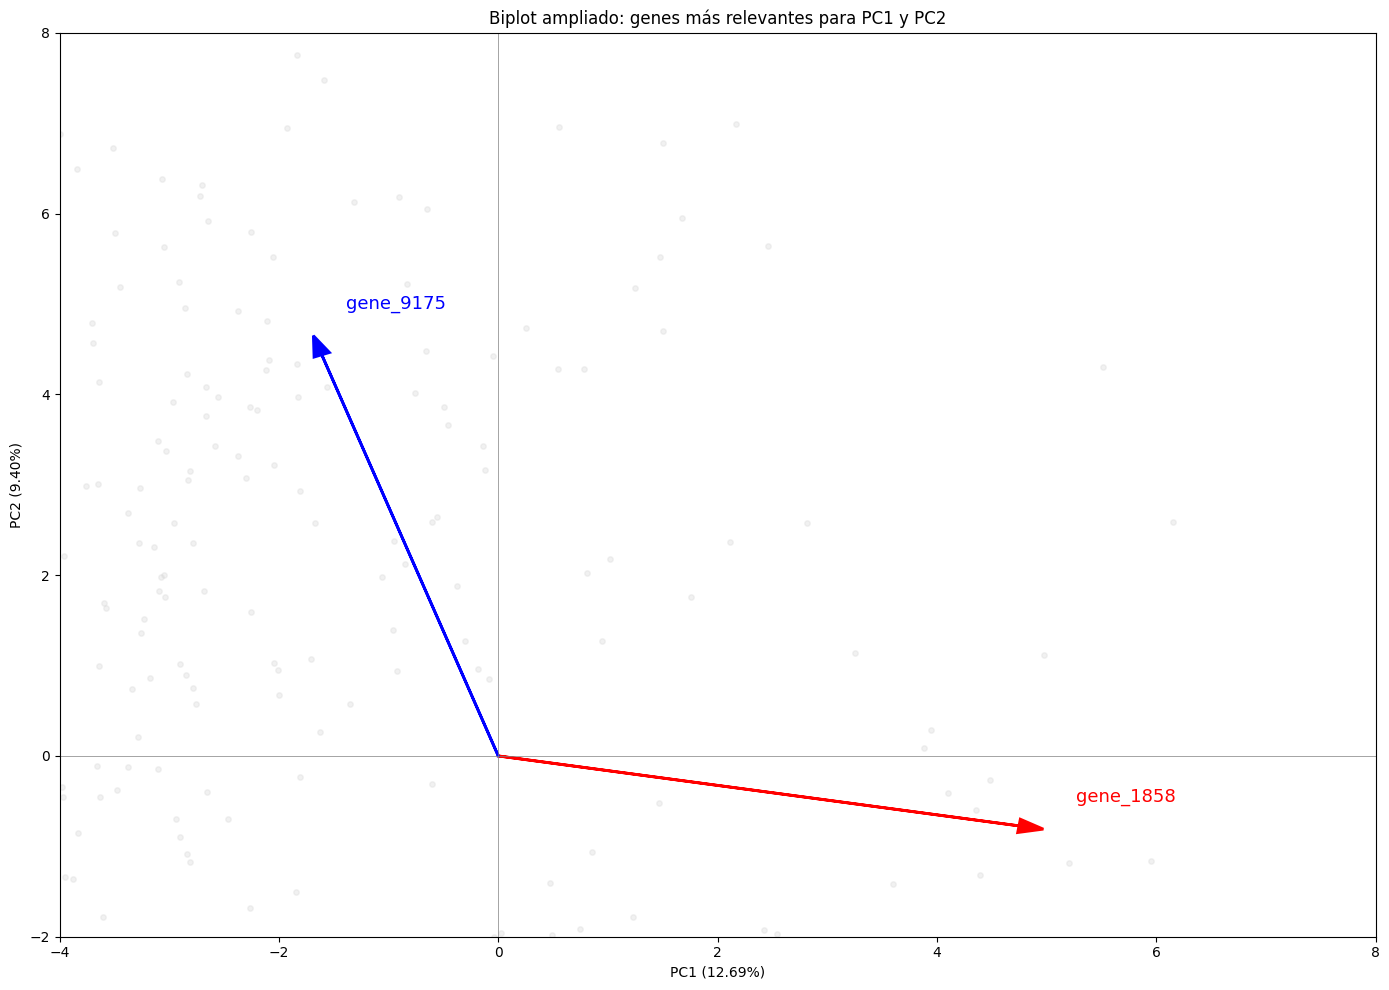

In [20]:

# Identificar los genes más relevantes
gen_pc1 = loadings_df["PC1"].abs().idxmax()
gen_pc2 = loadings_df["PC2"].abs().idxmax()

genes = [gen_pc1, gen_pc2]
colores = ["red", "blue"]

# Usar la misma escala de las flechas del biplot original
rango = max(np.ptp(X_pca[:, 0]), np.ptp(X_pca[:, 1]))
escala = rango * 0.16 / np.max(np.abs(loadings_df.loc[genes].values))

plt.figure(figsize=(14, 10))

# Graficar las muestras en gris para destacar las flechas
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    color="lightgray",
    alpha=0.3,
    s=15
)

# Dibujar los dos genes más relevantes
for gen, color in zip(genes, colores):
    lx = loadings_df.loc[gen, "PC1"]
    ly = loadings_df.loc[gen, "PC2"]

    plt.arrow(
        0, 0,
        lx * escala,
        ly * escala,
        color=color,
        head_width=0.15,
        linewidth=2,
        length_includes_head=True
    )

    plt.text(
        lx * escala + 0.3,
        ly * escala + 0.3,
        gen,
        color=color,
        fontsize=13
    )

# Ampliar la zona donde están las flechas
plt.xlim(-4, 8)
plt.ylim(-2, 8)

plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
plt.title("Biplot ampliado: genes más relevantes para PC1 y PC2")

plt.tight_layout()
plt.show()


Los genes más importantes tanto para PC1 como para PC2 coinciden con los vectores de carga

## Paso 7. Aplicar K-Means


Vamos a pedirle a K-Means que agrupe las 801 muestras según sus semejanzas genéticas, sin decirle a qué tipo de cáncer pertenece cada una.

Después comprobaremos si esos grupos están bien separados mediante Silhouette.

El índice `Silhouette` se utiliza para evaluar qué tan bien se agrupan las muestras en un análisis de clustering, como K-Means. Mide si las muestras están cerca de las de su propio grupo y alejadas de las de otros grupos.

Sus valores van de −1 a 1:
- Cercano a 1: los grupos están bien separados.
- Cercano a 0: los grupos se superponen o no están claramente diferenciados.
- Cercano a −1: las muestras podrían estar asignadas a grupos incorrectos.

In [8]:
# Conservamos los primeros 157 componentes
X_agrupamiento = X_pca_200[:, :cantidad]

# Buscamos 5 grupos
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
grupos = kmeans.fit_predict(X_agrupamiento)

# Evaluamos qué tan separados están
silhouette = silhouette_score(X_agrupamiento, grupos)

print("Cantidad de grupos encontrados:", len(set(grupos)))
print("Silhouette:", round(silhouette, 3))


Cantidad de grupos encontrados: 5
Silhouette: 0.226


Logramos agrupar las 801 muestras de cáncer según sus características genéticas, pero los cinco grupos no están muy bien separados. Esto significa que algunas muestras comparten características con otros grupos. Sin embargo, todavía no sabemos si esos grupos coinciden con los cinco tipos de cáncer reales.

## Paso 9. Comparar los grupos con los diagnósticos reales


Vamos a comprobar si cada grupo encontrado por K-Means corresponde principalmente a un tipo de cáncer. Así sabremos si los agrupamientos tienen sentido.

In [9]:
# Creamos una tabla comparativa
comparacion = pd.crosstab(
    grupos,
    etiquetas["Class"],
    rownames=["Grupo K-Means"],
    colnames=["Tipo de cáncer"]
)

print("Cantidad de muestras por grupo:")
display(comparacion)

# Calculamos los porcentajes dentro de cada grupo
print("\nPorcentajes dentro de cada grupo:")
display((comparacion.div(comparacion.sum(axis=1), axis=0) * 100).round(1))


Cantidad de muestras por grupo:


Tipo de cáncer,BRCA,COAD,KIRC,LUAD,PRAD
Grupo K-Means,,,,,
0,53,4,1,141,0
1,0,0,145,0,0
2,247,0,0,0,0
3,0,0,0,0,136
4,0,74,0,0,0



Porcentajes dentro de cada grupo:


Tipo de cáncer,BRCA,COAD,KIRC,LUAD,PRAD
Grupo K-Means,,,,,
0,26.6,2.0,0.5,70.9,0.0
1,0.0,0.0,100.0,0.0,0.0
2,100.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,100.0
4,0.0,100.0,0.0,0.0,0.0


 Aunque el Silhouette fue bajo (0,226), K-Means logró formar grupos que coinciden bastante bien con los tipos de cáncer reales. Cuatro grupos contienen exclusivamente muestras de un mismo cáncer, mientras que el grupo de pulmón también incluye algunas muestras de otros tipos, principalmente mama. En total, el 92,8 % de las muestras pertenece al tipo de cáncer predominante de su grupo. Esto indica que existen diferencias importantes en la expresión genética de los cinco cánceres.

**El grupo 0** es el único mezclado: contiene principalmente cáncer de pulmón, pero también 53 muestras de mama y algunas de colon y riñón, como veiamos en el grafico de PCA.

## Paso 9. Comprobar qué tan bien agrupó K-Means


Vamos a calcular el índice `ARI`, que compara los cinco grupos encontrados por K-Means con los cinco diagnósticos reales.

A diferencia de Silhouette, que mide qué tan separados están los grupos, ARI mide cuánto coinciden con los tipos de cáncer verdaderos.

In [10]:
# Comparamos los grupos con los diagnósticos reales
ari = adjusted_rand_score(y, grupos)

print("Índice ARI:", round(ari, 3))


Índice ARI: 0.809


¿Cómo interpretamos el ARI?
- Cercano a 1: los grupos coinciden muy bien con los diagnósticos.
- Cercano a 0: la coincidencia no es mejor que la esperada por azar.

Obtuvimos un índice ARI de 0,809, lo que indica una coincidencia alta entre los grupos encontrados por K-Means y los diagnósticos reales.

**Esto responde parcialmente a la pregunta 5: ¿Qué tipos de cáncer presentan características genéticas más parecidas y cuáles son más diferentes?**

Encontramos que mama y pulmón presentan mayor mezcla entre sus muestras, mientras que riñón, próstata y colon forman grupos más definidos.

##Paso 10. Clasificar los cinco cánceres con Random Forest


Hasta ahora buscamos semejanzas sin decirle al algoritmo qué cáncer tenía cada muestra. Ahora vamos a entrenar Random Forest con los diagnósticos conocidos para comprobar si puede identificar correctamente el tipo de cáncer en muestras que no vio antes.

Muestras = pacientes o tumores analizados. Tenemos 801 muestras de cinco tipos de cáncer: mama, colon, riñón, pulmón y próstata.



Genes = características que medimos en cada muestra. Tenemos 20.531 valores de expresión genética por muestra.

5 clases

Primero vamos a utilizar la totalidad de genes: los 20.530.

In [31]:

# Definir el modelo Random Forest con evaluación OOB
rf_model = RandomForestClassifier(
    n_estimators=1000,  # Cantidad de árboles
    oob_score=True,     # Evaluación Out-Of-Bag
    random_state=0
)

# Entrenar con las 801 muestras y los 20531 genes
rf_model.fit(X, y) #y contiene las clases

# Mostrar un resumen del modelo
print("Resumen del modelo Random Forest:")
print("Número de árboles:", rf_model.n_estimators)
print("Precisión OOB:", rf_model.oob_score_)
print("Número de características:", rf_model.n_features_in_)
print("Clases:", rf_model.classes_)


Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.9950062421972534
Número de características: 20531
Clases: [0 1 2 3 4]


Random Forest obtuvo una precisión OOB del 99,50 % al clasificar cinco tipos de cáncer a partir de 20.531 características de expresión genética, lo que indica un rendimiento muy alto dentro del dataset analizado.

###Realizamos una matriz de confusión OOB

Matriz de confusión OOB:


,Mama,Colon,Riñón,Pulmón,Próstata
Mama,300,0,0,0,0
Colon,0,78,0,0,0
Riñón,1,0,145,0,0
Pulmón,3,0,0,138,0
Próstata,0,0,0,0,136


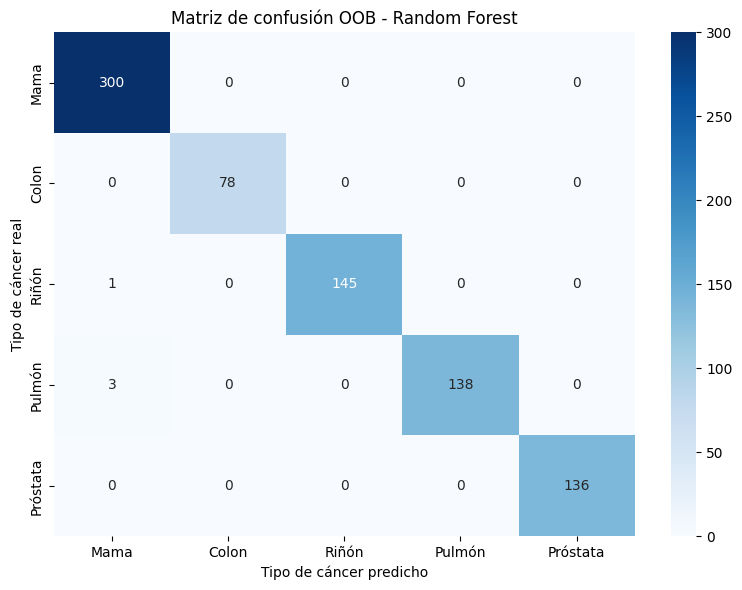

In [32]:
from sklearn.metrics import confusion_matrix
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir las probabilidades OOB a etiquetas de clase
oob_predicted_labels = rf_model.classes_[
    np.argmax(oob_predictions, axis=1)
]

# Crear la matriz de confusión
conf_matrix = confusion_matrix(
    y,
    oob_predicted_labels,
    labels=rf_model.classes_
)

# Nombres de los cinco tipos de cáncer
clases = ["Mama", "Colon", "Riñón", "Pulmón", "Próstata"]

# Convertir la matriz a un DataFrame
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=clases,
    columns=clases
)

print("Matriz de confusión OOB:")
display(conf_matrix_df)

# Representar la matriz gráficamente
plt.figure(figsize=(8, 6))

sns.heatmap(
    conf_matrix_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Tipo de cáncer predicho")
plt.ylabel("Tipo de cáncer real")
plt.title("Matriz de confusión OOB - Random Forest")

plt.tight_layout()
plt.show()


Observamos que Random Forest cometió solamente 4 errores de las 801 muestras:
- 3 muestras de cáncer de pulmón fueron clasificadas incorrectamente como cáncer de mama.
- 1 muestra de cáncer de riñón fue clasificada como cáncer de mama.

Algo interesante es que en el gráfico de PCA vimos que las muestras e cáncer de mama (azul) y cáncer de pulmón (rojo) se superponian un poco pero alcanzabamos un porcentaje muy bajo de varianza entre PC1 y PC2.Sin embargo, Random Forest presentó errores justamente en esas clases, con un OOB=99,50%.



### Ordenamos las carcaterísticas por importancia:

In [33]:

# Obtener la importancia de las 20.531 características
feature_importance = rf_model.feature_importances_

# Obtener los nombres de los genes
feature_names = X.columns

# Ordenar los índices de mayor a menor importancia
sorted_idx = np.argsort(feature_importance)[::-1]

# Ordenar los valores de importancia
sorted_feature_importance = feature_importance[sorted_idx]

# Ordenar los nombres de los genes
sorted_feature_names = np.array(feature_names)[sorted_idx]

# Mostrar los 10 genes más importantes
print("Los 10 genes más importantes para Random Forest:")

for feature, importance in zip(
    sorted_feature_names[:10],
    sorted_feature_importance[:10]
):
    print(f"{feature}: {importance:.6f}")


Los 10 genes más importantes para Random Forest:
gene_18746: 0.008716
gene_7964: 0.006950
gene_17801: 0.006922
gene_15589: 0.006382
gene_15987: 0.005239
gene_15898: 0.004475
gene_17904: 0.004438
gene_9652: 0.004093
gene_8014: 0.003899
gene_5407: 0.003814


Esta importancia indica cuánto contribuyó cada gen a las decisiones de los árboles del modelo

### Gráficamente:

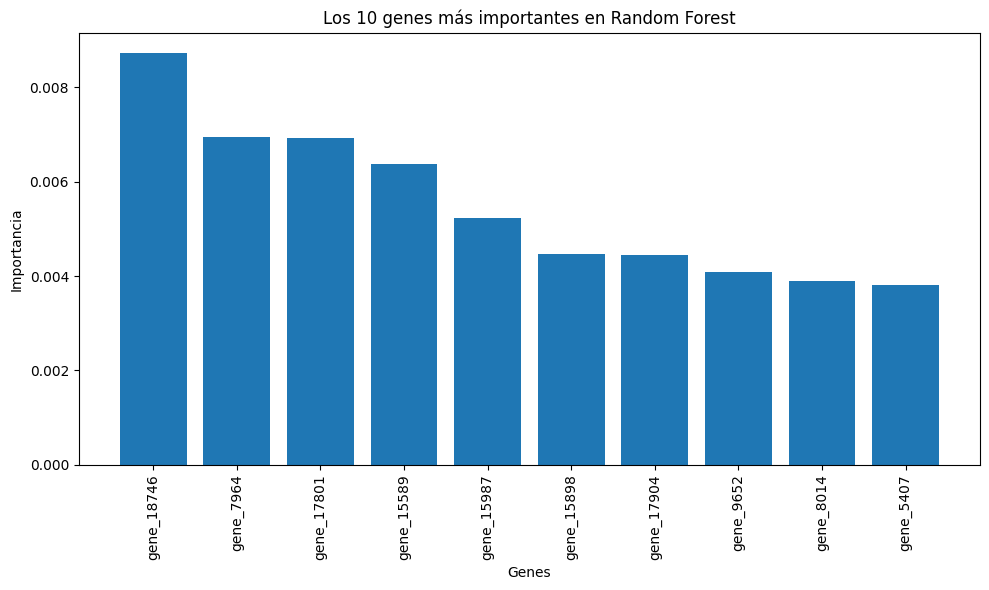

In [34]:

# Crear gráfico de barras de los 10 genes más importantes

plt.figure(figsize=(10, 6))

# Graficar la importancia de los primeros 10 genes
plt.bar(
    range(10),
    sorted_feature_importance[:10]
)

# Colocar los nombres de los genes
plt.xticks(
    range(10),
    sorted_feature_names[:10],
    rotation=90
)

# Títulos y etiquetas
plt.xlabel("Genes")
plt.ylabel("Importancia")
plt.title("Los 10 genes más importantes en Random Forest")

plt.tight_layout()
plt.show()


#Paso 11. Comparamos con árbol de decision

Dividimos el dataset en conjunto de entrenamiento y conjunto de test o prueba

In [36]:

# Dividir el dataset en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% para prueba
    random_state=42,
    stratify=y          # Mantener la proporción de los 5 tipos de cáncer
)

# Verificar la cantidad de muestras y genes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (640, 20531)
X_test: (161, 20531)
y_train: (640,)
y_test: (161,)


In [37]:

# Importar el clasificador de Árbol de Decisión
from sklearn.tree import DecisionTreeClassifier

# Definir el modelo
clf = DecisionTreeClassifier(
    criterion="entropy",
    min_impurity_decrease=0.03,
    random_state=0,
    min_samples_leaf=5
)

# Entrenar el modelo con los datos de entrenamiento
clf.fit(X_train, y_train)


DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.03,
                       min_samples_leaf=5, random_state=0)

In [38]:

# Predecir las etiquetas de los datos de prueba
y_pred = clf.predict(X_test)

# Calcular la precisión del modelo
accuracy = accuracy_score(
    y_test,
    y_pred
)

# Imprimir la precisión del modelo
print("Precisión del modelo: {:.2f}".format(accuracy))


Precisión del modelo: 0.96


In [39]:

# Imprimir información sobre el árbol
print(f"Profundidad del árbol: {clf.get_depth()}")
print(f"Número de hojas: {clf.get_n_leaves()}")


Profundidad del árbol: 3
Número de hojas: 6


Veamos cuáles fueron las características mas importantes para el árbol de decisión

In [40]:

# Obtener la importancia de los 20.531 genes
importances = clf.feature_importances_

# Ordenar los índices de mayor a menor importancia
sorted_indices = np.argsort(importances)[::-1]

print("Genes más importantes en el árbol de decisión:")

# Mostrar solamente los genes que utilizó el árbol
for idx in sorted_indices:
    feature_name = X.columns[idx]
    importance = importances[idx]

    if importance > 0:
        print(f"{feature_name}: {importance:.4f}")


Genes más importantes en el árbol de decisión:
gene_7896: 0.4074
gene_9175: 0.2323
gene_7379: 0.1986
gene_16283: 0.1147
gene_15895: 0.0470


###Comparamos los genes más importantes de árbol de decisión y Random Forest

In [41]:

# Crear una tabla comparativa de los genes más importantes
comparacion = pd.DataFrame({
    "Árbol de decisión": [
        "gene_7896", "gene_9175", "gene_7379",
        "gene_16283", "gene_15895"
    ],
    "Random Forest": [
        "gene_18746", "gene_7964", "gene_17801",
        "gene_15589", "gene_15987"
    ]
})

print("Comparación de genes más importantes:")
display(comparacion)

# Identificar genes en común
genes_comunes = set(comparacion["Árbol de decisión"]) & set(comparacion["Random Forest"])

print("Genes en común:", genes_comunes if genes_comunes else "Ninguno")


Comparación de genes más importantes:


,Árbol de decisión,Random Forest
0,gene_7896,gene_18746
1,gene_9175,gene_7964
2,gene_7379,gene_17801
3,gene_16283,gene_15589
4,gene_15895,gene_15987


Genes en común: Ninguno


Si bien seleccionamos los 10 genes más importantes en Random Forest, tampoco coinciden los 5 restantes que no están en el cuadro.

La no coincidencia puede deberse a que los algoritmos funciona diferentes: árbol de decisión construyó 1 árbol y de todos los genes, seleccionó solo 5 para su construcción. En cambio Random Forest usó 1000 árboles con OOB=True, por eso la importancia está distribuida en entre muchas caracteristicas/genes.

Ademas entrenamos el árbol con 640 muestras y random forest usó las 801 muestras.

Pero encontramos 1 coincidencia con PCA:


*   Gene_9175

Es el de mayor carga absoluta en PC2 y el segundo mas importante en árbol de decisión.




#Paso 12. Análisis con Máquinas de Vcetores de Soporte

En esta etapa aplicaremos **SVM**, un algoritmo de aprendizaje supervisado que busca separar las clases mediante fronteras de decisión. Nuestro objetivo es clasificar las **801 muestras en cinco tipos de cáncer**, utilizando los valores de expresión de los 20.531 genes.

**Train (entrenamiento):** datos que el modelo usa para aprender.

**Validation (validación):** datos que usamos para probar distintas configuraciones o hiperparámetros y elegir la mejor.

**Test (prueba):** datos que se guardan hasta el final para evaluar qué tan bien funciona el modelo con datos que nunca vio.

En el código primero separamos 80% train y 20% test, y después dividimos ese 80% de train otra vez para obtener train real + validation.
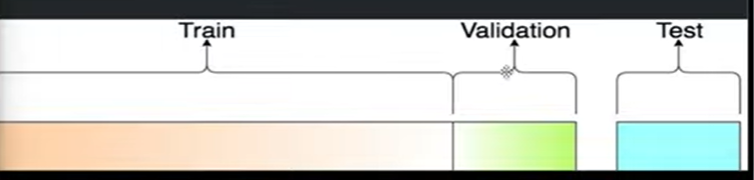

Como antes ya habiamos divido el dataset en entrenamiento y prueba en arbol de decision, ahor avamos a dividir el conjunto de entrenamiento para obtener el conjunto de validacion.

In [42]:

# Subdividir el conjunto de entrenamiento en train y validación
X_train_svm, X_val, y_train_svm, y_val = train_test_split(
    X_train,
    y_train,
    train_size=0.8, #usamos el 80% para entrenar y el 20% para testear
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Tamaño del conjunto de entrenamiento:", len(X_train_svm))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))


Tamaño del conjunto de entrenamiento: 512
Tamaño del conjunto de validación: 128
Tamaño del conjunto de prueba: 161


In [43]:

# Nombres de los cinco tipos de cáncer
nombres_clases = {
    0: "Mama",
    1: "Colon",
    2: "Riñón",
    3: "Pulmón",
    4: "Próstata"
}

# Mostrar la frecuencia de las clases en cada conjunto
print("Frecuencia de clases en entrenamiento:")
print(pd.Series(y_train_svm).map(nombres_clases).value_counts())

print("\nFrecuencia de clases en validación:")
print(pd.Series(y_val).map(nombres_clases).value_counts())

print("\nFrecuencia de clases en prueba:")
print(pd.Series(y_test).map(nombres_clases).value_counts())


Frecuencia de clases en entrenamiento:
Mama        192
Riñón        93
Pulmón       90
Próstata     87
Colon        50
Name: count, dtype: int64

Frecuencia de clases en validación:
Mama        48
Pulmón      23
Riñón       23
Próstata    22
Colon       12
Name: count, dtype: int64

Frecuencia de clases en prueba:
Mama        60
Riñón       30
Pulmón      28
Próstata    27
Colon       16
Name: count, dtype: int64


Importante: cada muestra sigue teniendo sus 20.531 genes. Lo único que estamos dividiendo son las muestras (filas), no las características (columnas).


###Valor C
El valor C indica cuanto penaliza el modelo los errores:

In [44]:

# Valores de C a evaluar
valores_C = np.logspace(-5, 5, num=11)

# Mostrar los valores
print("Valores de C:")
print(valores_C)


Valores de C:
[1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04
 1.e+05]


###Probamos Kernel Radial

Mejor valor de C: 1.0
Precisión máxima: 0.984375
Error mínimo en validación: 1.56%


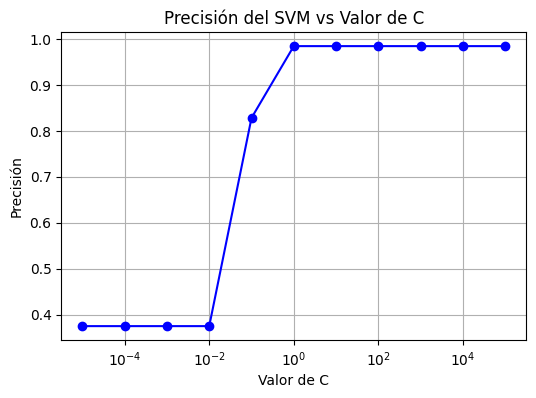


Resultados en el conjunto de prueba:
Mejor valor de C utilizado: 1.0
Precisión en test: 0.9813664596273292
Error en test: 1.86%

Matriz de Confusión:
[[60  0  0  0  0]
 [ 1 15  0  0  0]
 [ 0  0 30  0  0]
 [ 2  0  0 26  0]
 [ 0  0  0  0 27]]

Reporte de Clasificación:
              precision    recall  f1-score   support

        Mama       0.95      1.00      0.98        60
       Colon       1.00      0.94      0.97        16
       Riñón       1.00      1.00      1.00        30
      Pulmón       1.00      0.93      0.96        28
    Próstata       1.00      1.00      1.00        27

    accuracy                           0.98       161
   macro avg       0.99      0.97      0.98       161
weighted avg       0.98      0.98      0.98       161



In [45]:

# Importar SVM y métricas
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:

    # Entrenar el modelo SVM con kernel radial
    modelo_svm = make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=C)
    )

    modelo_svm.fit(X_train_svm, y_train_svm)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=mejor_C)
)

modelo_svm_final.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)

error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Mejor valor de C utilizado: {mejor_C}")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test)

# Crear reporte de clasificación
reporte_clasificacion = classification_report(
    y_test,
    predicciones_test,
    target_names=["Mama", "Colon", "Riñón", "Pulmón", "Próstata"]
)

print("\nMatriz de Confusión:")
print(matriz_confusion)

print("\nReporte de Clasificación:")
print(reporte_clasificacion)


##Probamos Kernel Polinomial

Mejor valor de C: 10.0
Precisión máxima: 0.9765625
Error mínimo en validación: 2.34%


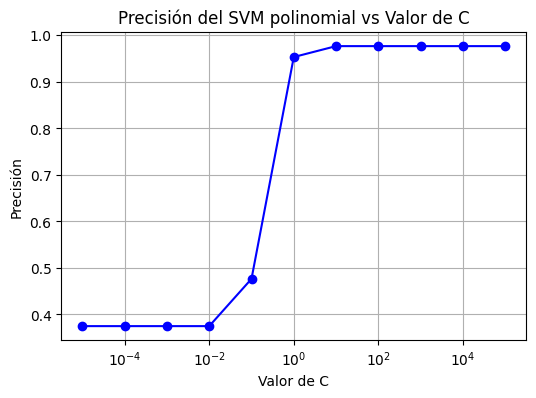


Resultados en el conjunto de prueba:
Mejor valor de C utilizado: 10.0
Precisión en test: 0.9254658385093167
Error en test: 7.45%

Matriz de Confusión:
[[60  0  0  0  0]
 [ 3 13  0  0  0]
 [ 5  0 25  0  0]
 [ 3  0  0 25  0]
 [ 1  0  0  0 26]]

Reporte de Clasificación:
              precision    recall  f1-score   support

        Mama       0.83      1.00      0.91        60
       Colon       1.00      0.81      0.90        16
       Riñón       1.00      0.83      0.91        30
      Pulmón       1.00      0.89      0.94        28
    Próstata       1.00      0.96      0.98        27

    accuracy                           0.93       161
   macro avg       0.97      0.90      0.93       161
weighted avg       0.94      0.93      0.93       161



In [46]:

# Inicializar una lista para almacenar las precisiones
precisiones_poly = []

# Bucle sobre los valores de C
for C in valores_C:

    # Entrenar el modelo SVM con kernel polinomial
    modelo_svm = make_pipeline(
        StandardScaler(),
        SVC(kernel='poly', C=C)
    )

    modelo_svm.fit(X_train_svm, y_train_svm)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones_poly.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C_poly = valores_C[np.argmax(precisiones_poly)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones_poly)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C_poly}")
print(f"Precisión máxima: {max(precisiones_poly)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones_poly, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM polinomial vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_poly = make_pipeline(
    StandardScaler(),
    SVC(kernel='poly', C=mejor_C_poly)
)

modelo_svm_poly.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test_poly = modelo_svm_poly.predict(X_test)

# Evaluar el rendimiento en el conjunto de prueba
precision_test_poly = accuracy_score(
    y_test,
    predicciones_test_poly
)

error_test_poly = 1 - precision_test_poly
error_porcentaje_test_poly = round(error_test_poly * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Mejor valor de C utilizado: {mejor_C_poly}")
print(f"Precisión en test: {precision_test_poly}")
print(f"Error en test: {error_porcentaje_test_poly}%")

# Crear matriz de confusión
matriz_confusion_poly = confusion_matrix(
    y_test,
    predicciones_test_poly
)

# Reporte de clasificación
reporte_clasificacion_poly = classification_report(
    y_test,
    predicciones_test_poly,
    target_names=["Mama", "Colon", "Riñón", "Pulmón", "Próstata"]
)

print("\nMatriz de Confusión:")
print(matriz_confusion_poly)

print("\nReporte de Clasificación:")
print(reporte_clasificacion_poly)


In [47]:

# Crear tabla comparativa de los dos modelos SVM
comparacion_svm = pd.DataFrame({
    "SVM radial (RBF)": [
        mejor_C,
        max(precisiones) * 100,
        precision_test * 100,
        (1 - precision_test) * 100,
        round(precision_test * len(y_test))
    ],
    "SVM polinomial": [
        mejor_C_poly,
        max(precisiones_poly) * 100,
        precision_test_poly * 100,
        (1 - precision_test_poly) * 100,
        round(precision_test_poly * len(y_test))
    ]
}, index=[
    "Mejor valor de C",
    "Precisión en validación (%)",
    "Precisión en prueba (%)",
    "Error en prueba (%)",
    "Muestras bien clasificadas"
])

# Mostrar la tabla
print("Comparación de SVM radial y polinomial:")
display(comparacion_svm.round(2))


Comparación de SVM radial y polinomial:


,SVM radial (RBF),SVM polinomial
Mejor valor de C,1.00,10.00
Precisión en validación (%),98.44,97.66
Precisión en prueba (%),98.14,92.55
Error en prueba (%),1.86,7.45
Muestras bien clasificadas,158.00,149.00


Al analizar las matrices de confusión:
- Kernel radial: confundió 2 muestras de pulmón y 1 de colon con cáncer de mama.
- Kernel polinomial: confundió 3 de colon, 5 de riñón, 3 de pulmón y 1 de próstata con cáncer de mama.

El SVM con kernel radial presentó un mejor rendimiento, alcanzando una precisión del 98,14 % en el conjunto de prueba, frente al 92,55 % del kernel polinomial. Además, ambos modelos mostraron una tendencia a clasificar erróneamente algunas muestras como cáncer de mama, especialmente el polinomial.

#Paso 13. Análisis de deep learning (Redes Neuronales)

###Definimos la red neuronal

In [48]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Definir la red neuronal
model = models.Sequential()

# Capa de entrada: 20.531 genes
model.add(layers.Input(shape=(20531,)))

# Primera capa oculta
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

# Segunda capa oculta
model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

# Tercera capa oculta
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())

# Capa de salida: 5 tipos de cáncer
model.add(layers.Dense(5, activation='softmax'))

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

# Mostrar la estructura de la red neuronal
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     5,256,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,299,461 (20.22 MB)

 Trainable params: 5,298,565 (20.21 MB)

 Non-trainable params: 896 (3.50 KB)

In [49]:

# Estandarizar los valores de expresión de los genes
scaler_nn = StandardScaler()

X_train_nn = scaler_nn.fit_transform(X_train_svm).astype("float32")
X_val_nn = scaler_nn.transform(X_val).astype("float32")

# Definir hiperparámetros
epocas = 20       # Recorrerá 20 veces el conjunto de entrenamiento
batch_size = 32   # Procesará las muestras en grupos de 32

# Entrenar el modelo y almacenar el historial
history = model.fit(
    X_train_nn,
    y_train_svm,
    epochs=epocas,
    batch_size=batch_size,
    validation_data=(X_val_nn, y_val)
)


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.7891 - loss: 0.6600 - val_accuracy: 0.9219 - val_loss: 0.3254
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9785 - loss: 0.1729 - val_accuracy: 0.9844 - val_loss: 0.0633
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9902 - loss: 0.0975 - val_accuracy: 0.9922 - val_loss: 0.0329
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9922 - loss: 0.0640 - val_accuracy: 0.9922 - val_loss: 0.0265
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9961 - loss: 0.0367 - val_accuracy: 0.9922 - val_loss: 0.0261
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9961 - loss: 0.0422 - val_accuracy: 0.9922 - val_loss: 0.0222
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9961 - loss: 0.0403 - val_accuracy: 0.9922 - val_loss: 0.0153
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9902 - loss: 0.0417 - val_accuracy: 0.9922 - v

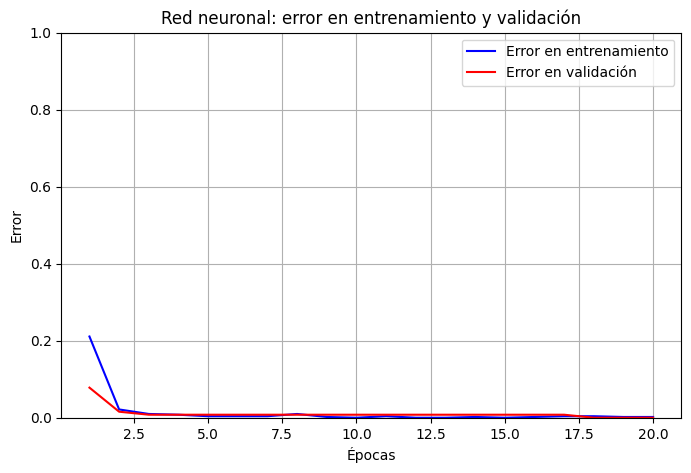

In [50]:

# Obtener los valores de accuracy y val_accuracy
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Obtener las curvas de error en entrenamiento y validación
Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

# Graficar las curvas de error
epochs = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, Error_train, 'b', label='Error en entrenamiento')
plt.plot(epochs, Error_val, 'r', label='Error en validación')

plt.title('Red neuronal: error en entrenamiento y validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()
plt.grid(True)

plt.show()


La red neuronal presentó un aprendizaje rápido, reduciendo el error de entrenamiento y validación a valores cercanos al 0 % durante las primeras épocas. Las curvas no mostraron señales evidentes de sobreajuste, lo que sugiere una buena capacidad de clasificación dentro del conjunto de datos analizado.

In [51]:

# Estandarizar los datos de prueba
X_test_nn = scaler_nn.transform(X_test).astype("float32")

# Evaluar el modelo con los datos de test
test_loss, test_accuracy = model.evaluate(X_test_nn, y_test)

# Imprimir los resultados
print(f"\nPérdida en Test: {test_loss:.4f}")
print(f"Precisión en Test: {test_accuracy * 100:.2f}%")


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9814 - loss: 0.0551 

Pérdida en Test: 0.0551
Precisión en Test: 98.14%


In [52]:

# Crear tabla comparativa de los modelos
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "SVM radial (RBF)",
        "SVM polinomial",
        "Red neuronal"
    ],
    "Precisión en test (%)": [
        precision_test * 100,
        precision_test_poly * 100,
        test_accuracy * 100
    ]
})

# Calcular el error de cada modelo
comparacion_modelos["Error en test (%)"] = (
    100 - comparacion_modelos["Precisión en test (%)"]
)

# Calcular la cantidad de muestras correctamente clasificadas
comparacion_modelos["Muestras correctas"] = (
    comparacion_modelos["Precisión en test (%)"] / 100 * len(y_test)
).round().astype(int)

# Mostrar la tabla comparativa
print("Comparación de modelos de clasificación:")
display(comparacion_modelos.round(2))


Comparación de modelos de clasificación:


,Modelo,Precisión en test (%),Error en test (%),Muestras correctas
0,SVM radial (RBF),98.14,1.86,158
1,SVM polinomial,92.55,7.45,149
2,Red neuronal,98.14,1.86,158


Veamos la matriz de confusión de la red neuronal, para saber dónde se equivocó

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Matriz de confusión de la red neuronal:


,Mama,Colon,Riñón,Pulmón,Próstata
Mama,60,0,0,0,0
Colon,0,15,0,1,0
Riñón,0,0,30,0,0
Pulmón,2,0,0,26,0
Próstata,0,0,0,0,27


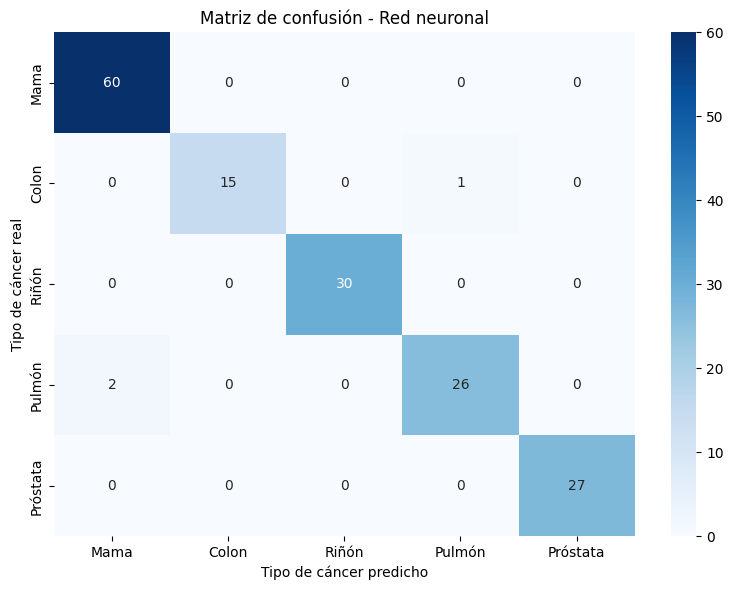

In [53]:

# Obtener las probabilidades predichas por la red neuronal
predicciones_nn = model.predict(X_test_nn)

# Convertir las probabilidades en clases (0, 1, 2, 3, 4)
y_pred_nn = np.argmax(predicciones_nn, axis=1)

# Crear la matriz de confusión
matriz_nn = confusion_matrix(y_test, y_pred_nn)

# Nombres de los cinco tipos de cáncer
nombres = ["Mama", "Colon", "Riñón", "Pulmón", "Próstata"]

# Convertir la matriz en un DataFrame
matriz_nn_df = pd.DataFrame(
    matriz_nn,
    index=nombres,
    columns=nombres
)

print("Matriz de confusión de la red neuronal:")
display(matriz_nn_df)

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_nn_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Tipo de cáncer predicho")
plt.ylabel("Tipo de cáncer real")
plt.title("Matriz de confusión - Red neuronal")

plt.tight_layout()
plt.show()


Comparación de los errores

In [54]:

# Nombres de los tipos de cáncer
nombres = ["Mama", "Colon", "Riñón", "Pulmón", "Próstata"]

# Función para identificar los errores de cada matriz
def mostrar_errores(matriz):
    errores = []

    for i in range(5):
        for j in range(5):
            if i != j and matriz[i, j] > 0:
                errores.append(
                    f"{matriz[i, j]} {nombres[i]} → {nombres[j]}"
                )

    return "; ".join(errores) if errores else "Sin errores"

# Crear tabla comparativa
comparacion_final = pd.DataFrame({
    "Modelo": [
        "Random Forest (OOB)",
        "SVM radial",
        "SVM polinomial",
        "Red neuronal"
    ],
    "Precisión (%)": [
        rf_model.oob_score_ * 100,
        precision_test * 100,
        precision_test_poly * 100,
        test_accuracy * 100
    ],
    "Errores de clasificación": [
        mostrar_errores(conf_matrix),
        mostrar_errores(matriz_confusion),
        mostrar_errores(matriz_confusion_poly),
        mostrar_errores(matriz_nn)
    ]
})

# Mostrar los resultados
print("Comparación de los modelos de clasificación:")
display(comparacion_final.round(2))


Comparación de los modelos de clasificación:


,Modelo,Precisión (%),Errores de clasificación
0,Random Forest (OOB),99.50,1 Riñón → Mama; 3 Pulmón → Mama
1,SVM radial,98.14,1 Colon → Mama; 2 Pulmón → Mama
2,SVM polinomial,92.55,3 Colon → Mama; 5 Riñón → Mama; 3 Pulmón → Mam...
3,Red neuronal,98.14,1 Colon → Pulmón; 2 Pulmón → Mama


Importante: Random Forest se evaluó mediante OOB con las 801 muestras, mientras que SVM y la red neuronal se evaluaron con 161 muestras de prueba. Por eso, sus precisiones no son directamente comparables.

# Paso 14. Validación cruzada con distintas cantidades de genes


Vamos a comprobar si Random Forest puede clasificar los cinco tipos de cáncer igual de bien utilizando menos genes.

Vamos a comparar 10, 15, 25, 50 y 20.531 genes.

In [57]:

# Cantidades de genes que queremos probar
cantidades_genes = [5, 10, 15, 25, 50]

# Entrenar Random Forest para identificar los genes importantes
selector = RandomForestClassifier(
    n_estimators=300,
    random_state=0,
    n_jobs=-1
)

selector.fit(X_train_svm, y_train_svm)

# Ordenar los genes por importancia
indices = np.argsort(selector.feature_importances_)[::-1]
genes_ordenados = X_train_svm.columns[indices]

# Guardar los resultados
resultados = []

for n in cantidades_genes:

    # Seleccionar los n genes más importantes
    genes = genes_ordenados[:n]

    # Entrenar Random Forest con esos genes
    modelo = RandomForestClassifier(
        n_estimators=300,
        random_state=0,
        n_jobs=-1
    )

    modelo.fit(X_train_svm[genes], y_train_svm)

    # Evaluar con las muestras de validación
    predicciones = modelo.predict(X_val[genes])
    precision = accuracy_score(y_val, predicciones)

    resultados.append({
        "Cantidad de genes": n,
        "Precisión en validación (%)": precision * 100
    })

# Crear tabla comparativa
tabla_validacion = pd.DataFrame(resultados)

print("Comparación de Random Forest con menos genes:")
display(tabla_validacion.round(2))

# Elegir la cantidad de genes con mayor precisión
mejor_n = tabla_validacion.sort_values(
    ["Precisión en validación (%)", "Cantidad de genes"],
    ascending=[False, True]
).iloc[0]["Cantidad de genes"]

mejor_n = int(mejor_n)

print("Cantidad de genes seleccionada:", mejor_n)


Comparación de Random Forest con menos genes:


,Cantidad de genes,Precisión en validación (%)
0,5,96.88
1,10,99.22
2,15,99.22
3,25,99.22
4,50,99.22


Cantidad de genes seleccionada: 10


In [58]:

# Identificar los genes importantes utilizando las 640 muestras
selector_final = RandomForestClassifier(
    n_estimators=300,
    random_state=0,
    n_jobs=-1
)

selector_final.fit(X_train, y_train)

indices = np.argsort(selector_final.feature_importances_)[::-1]
genes_finales = X_train.columns[indices[:mejor_n]]

# Entrenar Random Forest con los genes seleccionados
rf_reducido = RandomForestClassifier(
    n_estimators=1000,
    oob_score=True,
    random_state=0,
    n_jobs=-1
)

rf_reducido.fit(X_train[genes_finales], y_train)

# Evaluar con las 161 muestras de prueba
predicciones = rf_reducido.predict(X_test[genes_finales])

precision_final = accuracy_score(y_test, predicciones)

print("Cantidad de genes:", mejor_n)
print("Precisión en prueba:", round(precision_final * 100, 2), "%")
print("Precisión OOB:", round(rf_reducido.oob_score_ * 100, 2), "%")
print("Genes seleccionados:")
print(list(genes_finales))


Cantidad de genes: 10
Precisión en prueba: 96.89 %
Precisión OOB: 98.91 %
Genes seleccionados:
['gene_15987', 'gene_2747', 'gene_14092', 'gene_11903', 'gene_18746', 'gene_15895', 'gene_14798', 'gene_16246', 'gene_2288', 'gene_6611']


Evaluamos si Random Forest podía clasificar los cinco tipos de cáncer utilizando **5, 10, 15, 25 y 50 genes**, en lugar de los 20.531 originales. Obtuvimos una precisión en validación del **96,88 % con 5 genes** y del **99,22 % con 10, 15, 25 y 50 genes**. Por eso seleccionamos 10 genes, al ser la menor cantidad que alcanzó la máxima precisión. Finalmente, el modelo obtuvo un **96,89 % de precisión en prueba**, demostrando que es posible mantener un alto rendimiento utilizando muchas menos características.

# Paso 15. ¿Qué tipos de cáncer se parecen más genéticamente?


Vamos a comparar la expresión promedio de los 20.531 genes entre los cinco tipos de cáncer y crear un mapa de calor.

Interpretación del mapa:

Correlación cercana a 1: los perfiles promedio de expresión siguen patrones similares.



Correlación cercana a 0: presentan poca relación lineal.

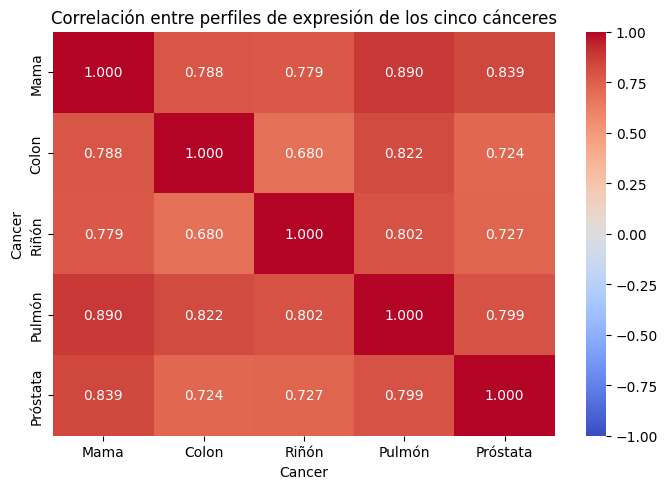

In [59]:

# Crear una tabla con los genes y el tipo de cáncer
datos_comparacion = pd.DataFrame(
    X_normalizado,
    columns=X.columns
)

datos_comparacion["Cancer"] = etiquetas["Class"].values

# Calcular la expresión promedio de cada gen por cáncer
promedios = datos_comparacion.groupby("Cancer").mean()

# Calcular la correlación entre los cinco tipos de cáncer
similitud = promedios.T.corr()

# Cambiar los códigos por nombres
similitud = similitud.rename(
    index=nombres_cancer,
    columns=nombres_cancer
)

# Graficar el mapa de calor
plt.figure(figsize=(7, 5))

sns.heatmap(
    similitud,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre perfiles de expresión de los cinco cánceres")
plt.tight_layout()
plt.show()


Vemos que:


- Mama y pulmón (0,890): presentan la correlación más alta entre dos tipos de cáncer diferentes. Sus perfiles promedio de expresión genética son los más parecidos según esta medida.
- Colon y riñón (0,680): presentan la correlación más baja.
- Todos los valores son positivos: los perfiles promedio de expresión de los cinco cánceres muestran cierta semejanza.

# CONCLUSION FINAL

En este proyecto analizamos **801 muestras de cinco tipos de cáncer y 20.531 genes**, con el objetivo de identificar patrones de expresión genética, determinar qué características permiten diferenciar los cánceres y evaluar distintos algoritmos de aprendizaje automático.

Mediante **PCA y K-Means** observamos patrones que permiten distinguir los tipos de cáncer, aunque algunas muestras presentaron superposición. En los modelos supervisados, **Random Forest alcanzó una precisión OOB del 99,50 %**, mientras que SVM radial y la red neuronal obtuvieron un **98,14 % de precisión en prueba**, superando al SVM polinomial (92,55 %). Sin embargo, la evaluación OOB y la realizada sobre el conjunto de prueba no son directamente comparables.

También investigamos si era necesario utilizar los 20.531 genes originales. Evaluamos modelos con **5, 10, 15, 25 y 50 genes** y seleccionamos 10, porque fueron la menor cantidad que alcanzó la máxima precisión en validación (99,22 %). Con estos 10 genes, Random Forest obtuvo un **96,89 % de precisión en prueba**, demostrando que es posible mantener un alto rendimiento utilizando muchas menos características.

Además, identificamos características genéticas relevantes para la clasificación. Sin embargo, como el dataset utiliza identificadores numéricos (`gene_...`) y no disponemos de una correspondencia biológica verificada, **no fue posible determinar con certeza los nombres reales ni las funciones de estos genes**.

Finalmente, el análisis de correlación mostró que **mama y pulmón presentan los perfiles promedio de expresión más similares (r = 0,890)**, mientras que colon y riñón presentan la menor semejanza (r = 0,680). Esto coincide con algunas superposiciones observadas en PCA y confusiones encontradas en los clasificadores, aunque no demuestra que exista una relación causal.

**En conclusión, las técnicas bioinformáticas permitieron diferenciar los cinco tipos de cáncer con alta precisión e identificar un conjunto reducido de características potencialmente relevantes para su clasificación.** No obstante, sería necesario verificar la identidad biológica de los genes y validar los resultados con datos independientes antes de considerar su aplicación clínica.